# Publication figures

This notebook reproduces only the assembled multi-panel figures of the manuscript
(Figures 2, 3 and 4). Every panel is drawn by the same code as the corresponding
single plot in `combined_plots.ipynb`; the cell it was taken from is named in each
panel function. Figure 1 is a pure schematic and is not produced here.

## Setup

In [1]:
%matplotlib inline

import os
import re
import string
import subprocess
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import uncertainties as unc
from lmfit import Model
from matplotlib.image import imread
from matplotlib.ticker import ScalarFormatter
from scipy.optimize import curve_fit
from uncertainties import umath
from uncertainties import unumpy as unp

import utils as uts
from main_data_processor import Data

In [2]:
equillibrium_constans_path = 'source_data/MacromoleculeEquilibria_Crowding'
complexation_data_path = 'source_data/IonCrowderComplexation/raw_data'
sodium_path = 'source_data/IonStrengthDependency/Na_FRET.csv'

all_data = Data(
    equillibrium_constans_path,
    complexation_data_path,
    sodium_path
)

complexation_data = all_data.EquillbriumConstantsObj
equillibrium_constants = all_data.SodiumCrowderComplexationObj

# Permanent master dataframe used throughout the notebook.
# Do not overwrite this variable in analysis-specific cells.
data = all_data.data.copy()

os.makedirs('./plots', exist_ok=True)

In [3]:
# styles
styles = {
    'buffer': {'x': [0], 'y': [1760000000], 'yerr': [311872000], 'color': '#868788', 'marker': '*', 'ms': 9.5, 'mec': '#000000', 'label': 'buffer'},
    'EGly': {'color': '#2d642a', 'marker': '.', 'ms': 14, 'mec': '#000000', 'label': 'EG'},
    'PEG200': {'color': '#b3daff', 'marker': 'd', 'ms': 8, 'mec': '#000000', 'label': 'PEG 200'},
    'PEG400': {'color': '#640024', 'marker': '^', 'ms': 8, 'mec': '#000000', 'label': 'PEG 400'},
    'PEG600': {'color': '#ff730f', 'marker': 'h', 'ms': 8.5, 'mec': '#000000', 'label': 'PEG 600'},
    'PEG1000': {'color': '#fed85d', 'marker': 'P', 'ms': 8, 'mec': '#000000', 'label': 'PEG 1k'},
    'PEG1500': {'color': '#142cd7', 'marker': 'p', 'ms': 8.5, 'mec': '#000000', 'label': 'PEG 1.5k'},
    'PEG3000': {'color': '#ac1416', 'marker': 's', 'ms': 6.5, 'mec': '#000000', 'label': 'PEG 3k'},
    'PEG6000': {'color': '#674ea7', 'marker': 'D', 'ms': 6, 'mec': '#000000', 'label': 'PEG 6k'},
    'PEG12000': {'color': '#709d74', 'marker': 'v', 'ms': 8, 'mec': '#000000', 'label': 'PEG 12k'},
    'PEG20000': {'color': '#00cccc', 'marker': 'X', 'ms': 8, 'mec': '#000000', 'label': 'PEG 20k'},
    'PEG35000': {'color': '#b28092', 'marker': 'H', 'ms': 8.5, 'mec': '#000000', 'label': 'PEG 35k'},
    'Dextran6000': {'color': '#ff2f4e', 'marker': '<', 'ms': 8, 'mec': '#000000', 'label': 'Dextran 6k'},
    'Dextran70000': {'color': '#bf94e4', 'marker': '>', 'ms': 8, 'mec': '#000000', 'label': 'Dextran 70k'},
    'Ficoll400000': {'color': '#dfb37f', 'marker': '*', 'ms': 10, 'mec': '#000000', 'label': 'Ficoll 400k'},
}

In [4]:
def quad_model(x, a0, a1, a2):
    return a0 + a1 * x + a2 * x**2


def extract_name_and_value_from_a_file(filename):
    base_name = os.path.splitext(filename)[0]
    parts = base_name.split('_')

    if len(parts) == 2 and 'p' in parts[1]:
        name = parts[0]
        number1, number2 = parts[1].split('p')
        value = float(f"{int(number1)}.{int(number2)}")
        return name, value, base_name

    return None, None, None


def make_K_fitting(alfa, gamma, v0, n=1):
    def K_fitting(x, K, D):
        sqrt_term = np.sqrt(
            ((-x / n - D - 1 / K)**2)
            - 4 * x / n * D
        )
        term1 = D - 0.5 * (
            x / n + D + 1 / K - sqrt_term
        )
        term2 = 1 + (gamma / alfa) * K * (
            x / n
            - 0.5 * (x / n + D + 1 / K - sqrt_term)
        )
        return alfa * v0 * term1 * term2

    return K_fitting


def crowder_name_sort_key(name):
    if name == 'EGly':
        return (0, 0)

    match = re.search(r'PEG(\d+)', name)
    if match:
        return (1, int(match.group(1)))

    return (2, name)


def compute_effective_donor_concentration(wt_percent, C_nominal=1e-8):
    rho_water = 0.99707
    rho_mix = 0.99707 + 0.0017441 * wt_percent

    V_water = 0.2 / rho_water
    m_mix = 0.2 / (100 - wt_percent) * 100
    V_mix = m_mix / rho_mix

    volume_factor = V_mix / V_water
    return C_nominal / volume_factor


def save_grouped_plot_images(plot_files, output_path, n_cols=3):
    n_files = len(plot_files)
    if n_files == 0:
        return

    n_rows = (n_files + n_cols - 1) // n_cols

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(5 * n_cols, 4.5 * n_rows)
    )
    axes = np.atleast_1d(axes).flatten()
    letters = list(string.ascii_lowercase)

    for i, (ax, file) in enumerate(zip(axes, plot_files)):
        img = imread(os.path.join('plots', file))
        ax.imshow(img)
        ax.axis('off')
        ax.text(
            0.02,
            1.03,
            f"{letters[i]}",
            transform=ax.transAxes,
            fontsize=15,
            fontweight='bold',
            va='top',
            ha='left'
        )

    for ax in axes[n_files:]:
        ax.axis('off')

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, transparent=True)
    plt.close()


def plot_styled_crowder_errorbars(
    plot_dataframe,
    x_column,
    y_column,
    *,
    positive_x=False,
    positive_y=False,
    nonzero_columns=(),
    positive_columns=()
):
    for crowder, style in styles.items():
        if crowder == 'buffer':
            continue

        crowder_df = plot_dataframe[
            plot_dataframe['crowder'] == crowder
        ].copy()

        required_columns = [
            x_column,
            y_column,
            *nonzero_columns,
            *positive_columns
        ]
        crowder_df = crowder_df.dropna(
            subset=required_columns
        )

        if crowder_df.empty:
            continue

        x = crowder_df[x_column].astype(float).values

        y, y_err = uts.get_float_uncertainty(
            crowder_df[y_column]
        )
        y = np.asarray(y, dtype=float)
        y_err = np.asarray(y_err, dtype=float)

        valid = (
            np.isfinite(x)
            & np.isfinite(y)
            & np.isfinite(y_err)
        )

        if positive_x:
            valid &= x > 0

        if positive_y:
            valid &= y > 0

        for column in nonzero_columns:
            values = crowder_df[column].astype(float).values
            valid &= np.isfinite(values) & (values != 0)

        for column in positive_columns:
            values = crowder_df[column].astype(float).values
            valid &= np.isfinite(values) & (values > 0)

        x = x[valid]
        y = y[valid]
        y_err = y_err[valid]

        if len(x) == 0:
            continue

        order = np.argsort(x)
        x = x[order]
        y = y[order]
        y_err = y_err[order]

        plt.errorbar(
            x,
            y,
            yerr=y_err,
            color=style['color'],
            marker=style['marker'],
            mfc=style['color'],
            mec=style['mec'],
            linestyle='none',
            lw=1,
            ms=style['ms'],
            elinewidth=1,
            capsize=3,
            capthick=1,
            label=style['label']
        )


def plot_styled_crowder_points(
    plot_dataframe,
    x_column,
    y_column,
    *,
    positive_x=False,
    positive_y=False
):
    for crowder, style in styles.items():
        if crowder == 'buffer':
            continue

        crowder_df = plot_dataframe[
            plot_dataframe['crowder'] == crowder
        ].dropna(
            subset=[x_column, y_column]
        ).copy()

        if crowder_df.empty:
            continue

        x = crowder_df[x_column].astype(float).values
        y = crowder_df[y_column].astype(float).values

        valid = np.isfinite(x) & np.isfinite(y)

        if positive_x:
            valid &= x > 0

        if positive_y:
            valid &= y > 0

        x = x[valid]
        y = y[valid]

        if len(x) == 0:
            continue

        order = np.argsort(x)
        x = x[order]
        y = y[order]

        plt.plot(
            x,
            y,
            color=style['color'],
            marker=style['marker'],
            mfc=style['color'],
            mec=style['mec'],
            linestyle='none',
            ms=style['ms'],
            label=style['label']
        )

In [5]:
project_root = Path.cwd()
ri_module_dir = (
    project_root
    / 'source_data'
    / 'MacromoleculeEquilibria_Crowding'
    / 'our_raw_results'
)
output_dir = project_root / 'plots'
output_dir.mkdir(parents=True, exist_ok=True)

if str(ri_module_dir) not in sys.path:
    sys.path.insert(0, str(ri_module_dir))

from ssDNA_hybdrization_equillibrium_constant import (
    calculate_RI_slope_with_error
)

_cwd = Path.cwd()
os.chdir(ri_module_dir)
try:
    df_RI = calculate_RI_slope_with_error()
finally:
    os.chdir(_cwd)

directory = (
    project_root
    / 'source_data'
    / 'MacromoleculeEquilibria_Crowding'
    / 'our_raw_results'
    / 'DNA-DNA_countrate_vs_crowder_concentration'
)

/media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/.venv/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/.venv/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/.venv/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/.venv/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpect

## Figure assembly helpers

In [6]:
# Publication figures are assembled from panels of the standard single-plot size,
# so that fonts and markers keep the proportions used throughout the analysis.
PANEL_W, PANEL_H = 7, 5.6
PANEL_LABEL_KW = dict(fontsize=26, fontweight='bold', va='bottom', ha='right')

# Assembled figures and the hand-drawn artwork live side by side.
figure_dir = project_root / 'publication_plots'
figure_dir.mkdir(parents=True, exist_ok=True)


def label_panel(ax, letter, x=None):
    """Put a bold panel letter above the left edge of an axes, in figure coordinates.

    Call it after the layout is final. An axes holding an image is shrunk by its aspect
    ratio, so `x` can be used to pin such a panel to the column below it instead.
    """
    fig = ax.get_figure()
    box = ax.get_position()
    x = box.x0 if x is None else x
    fig.text(x - 0.45 / fig.get_figwidth(), box.y1 + 0.10 / fig.get_figheight(),
             letter, **PANEL_LABEL_KW)
    return x


def render_svg(svg_path, width_px=6300):
    """Rasterize vector artwork with Inkscape, caching the result next to the SVG.

    Matplotlib can only place raster images inside an axes, so schematics kept as
    SVG are converted once and re-used until the SVG itself changes.
    """
    png_path = Path(svg_path).with_suffix('.png')
    if not png_path.exists() or png_path.stat().st_mtime < Path(svg_path).stat().st_mtime:
        subprocess.run(['inkscape', str(svg_path), '--export-type=png',
                        f'--export-width={width_px}', '-o', str(png_path)],
                       check=True, capture_output=True)
    return png_path


def export_svg_pdf(svg_path):
    """Convert vector artwork straight to PDF, so that it stays vector in the manuscript.

    Going through matplotlib would rasterize it, which is why this bypasses the figure
    machinery used for the data panels.
    """
    pdf_path = Path(svg_path).with_suffix('.pdf')
    subprocess.run(['inkscape', str(svg_path), '--export-type=pdf', '-o', str(pdf_path)],
                   check=True, capture_output=True)
    print(f'saved {pdf_path}')
    return pdf_path


def save_figure(fig, name):
    """Save an assembled figure as PNG and PDF."""
    for extension in ('png', 'pdf'):
        fig.savefig(figure_dir / f'{name}.{extension}', dpi=300,
                    transparent=True, bbox_inches='tight')
    print(f'saved {figure_dir / name}.png and .pdf')

In [7]:
# Parameters from DOI: 10.1021/jp806893a
V = 0.825
alpha = 0.49
temperature_log = 293.15
temperature = 298.15
N_A = 6.02214076e23

ssDNA_Rg = all_data.ssDNA_dimensions.ssDNA_parameters['Rg_nm']



# Shared dataframe for all scaling-law and effective-volume plots
plot_data = data.copy()

plot_data = plot_data[
    (plot_data['crowder wt. [%]'] < 50)
    & (plot_data['molar mass [g/mol]'] >= 3000)
    & (plot_data['concentration [M]'] > 0)
].copy()

# Characteristic concentration
plot_data['c*N_[ml/g]'] = (
    plot_data['No_mono'].astype(float) ** (-4 / 5)
    / V
)

# Reduced concentration
plot_data['x'] = (
    plot_data['mass_concentration_[g/mL]'].astype(float)
    / plot_data['c*N_[ml/g]']
)

# Logarithmic scaling-law coordinates
plot_data['log(x)'] = np.log10(plot_data['x'])

plot_data['osmotic_pressure'] = (
    8.314
    * temperature_log
    / (44 * V)
    * (
        plot_data['x']
        + alpha * plot_data['x'] ** (9 / 4)
    )
    * 10**7
)

plot_data['y'] = np.log10(
    plot_data['osmotic_pressure']
)

# Predicted osmotic pressure
plot_data['pi_[Pa]'] = (
    8.314
    * temperature
    / (44 * V)
    * (
        plot_data['x']
        + alpha * plot_data['x'] ** (9 / 4)
    )
    / plot_data['No_mono'].astype(float) ** (9 / 5)
    * 10**6
)

# Residual free-energy contribution
plot_data['rest_dG_[kJ/mol]'] = (
    plot_data['dG_exp_[kJ/mol]']
    - plot_data['dG_Na_[kJ/mol]']
)

# Effective molar volume
plot_data['dG_rest/pi_[m3/mol]'] = (
    -plot_data['rest_dG_[kJ/mol]']
    * 1000
    / plot_data['pi_[Pa]']
)

# Effective volume per molecule
plot_data['Veff_[nm3]'] = (
    plot_data['dG_rest/pi_[m3/mol]']
    * 10**27
    / N_A
)

# Correlation length
plot_data['xi_[nm]'] = (
    plot_data['Rg_[nm]']
    * plot_data['c/c*'] ** (-0.77)
)

# Normalized effective volume
plot_data['V_eff/(Rg xi)_[nm]'] = (
    plot_data['Veff_[nm3]']
    / (
        plot_data['Rg_[nm]']
        * plot_data['xi_[nm]']
    )
)




plot_data['V_eff/(Rg xi RgssDNA)_[nm]'] = (
    plot_data['Veff_[nm3]']
    / (
        plot_data['Rg_[nm]'] * plot_data['xi_[nm]'] * ssDNA_Rg
    )
)

## Figure 1 - Conceptual framework

Figure 1 carries no data: it was drawn by hand and cut out of
`helping_files/new_Adam/molecular_crowding.svg` into `publication_plots/figure1.svg`.
Here it is only converted to the PDF used by the manuscript; the preview
below is a rasterization of that same file.

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/figure1.pdf


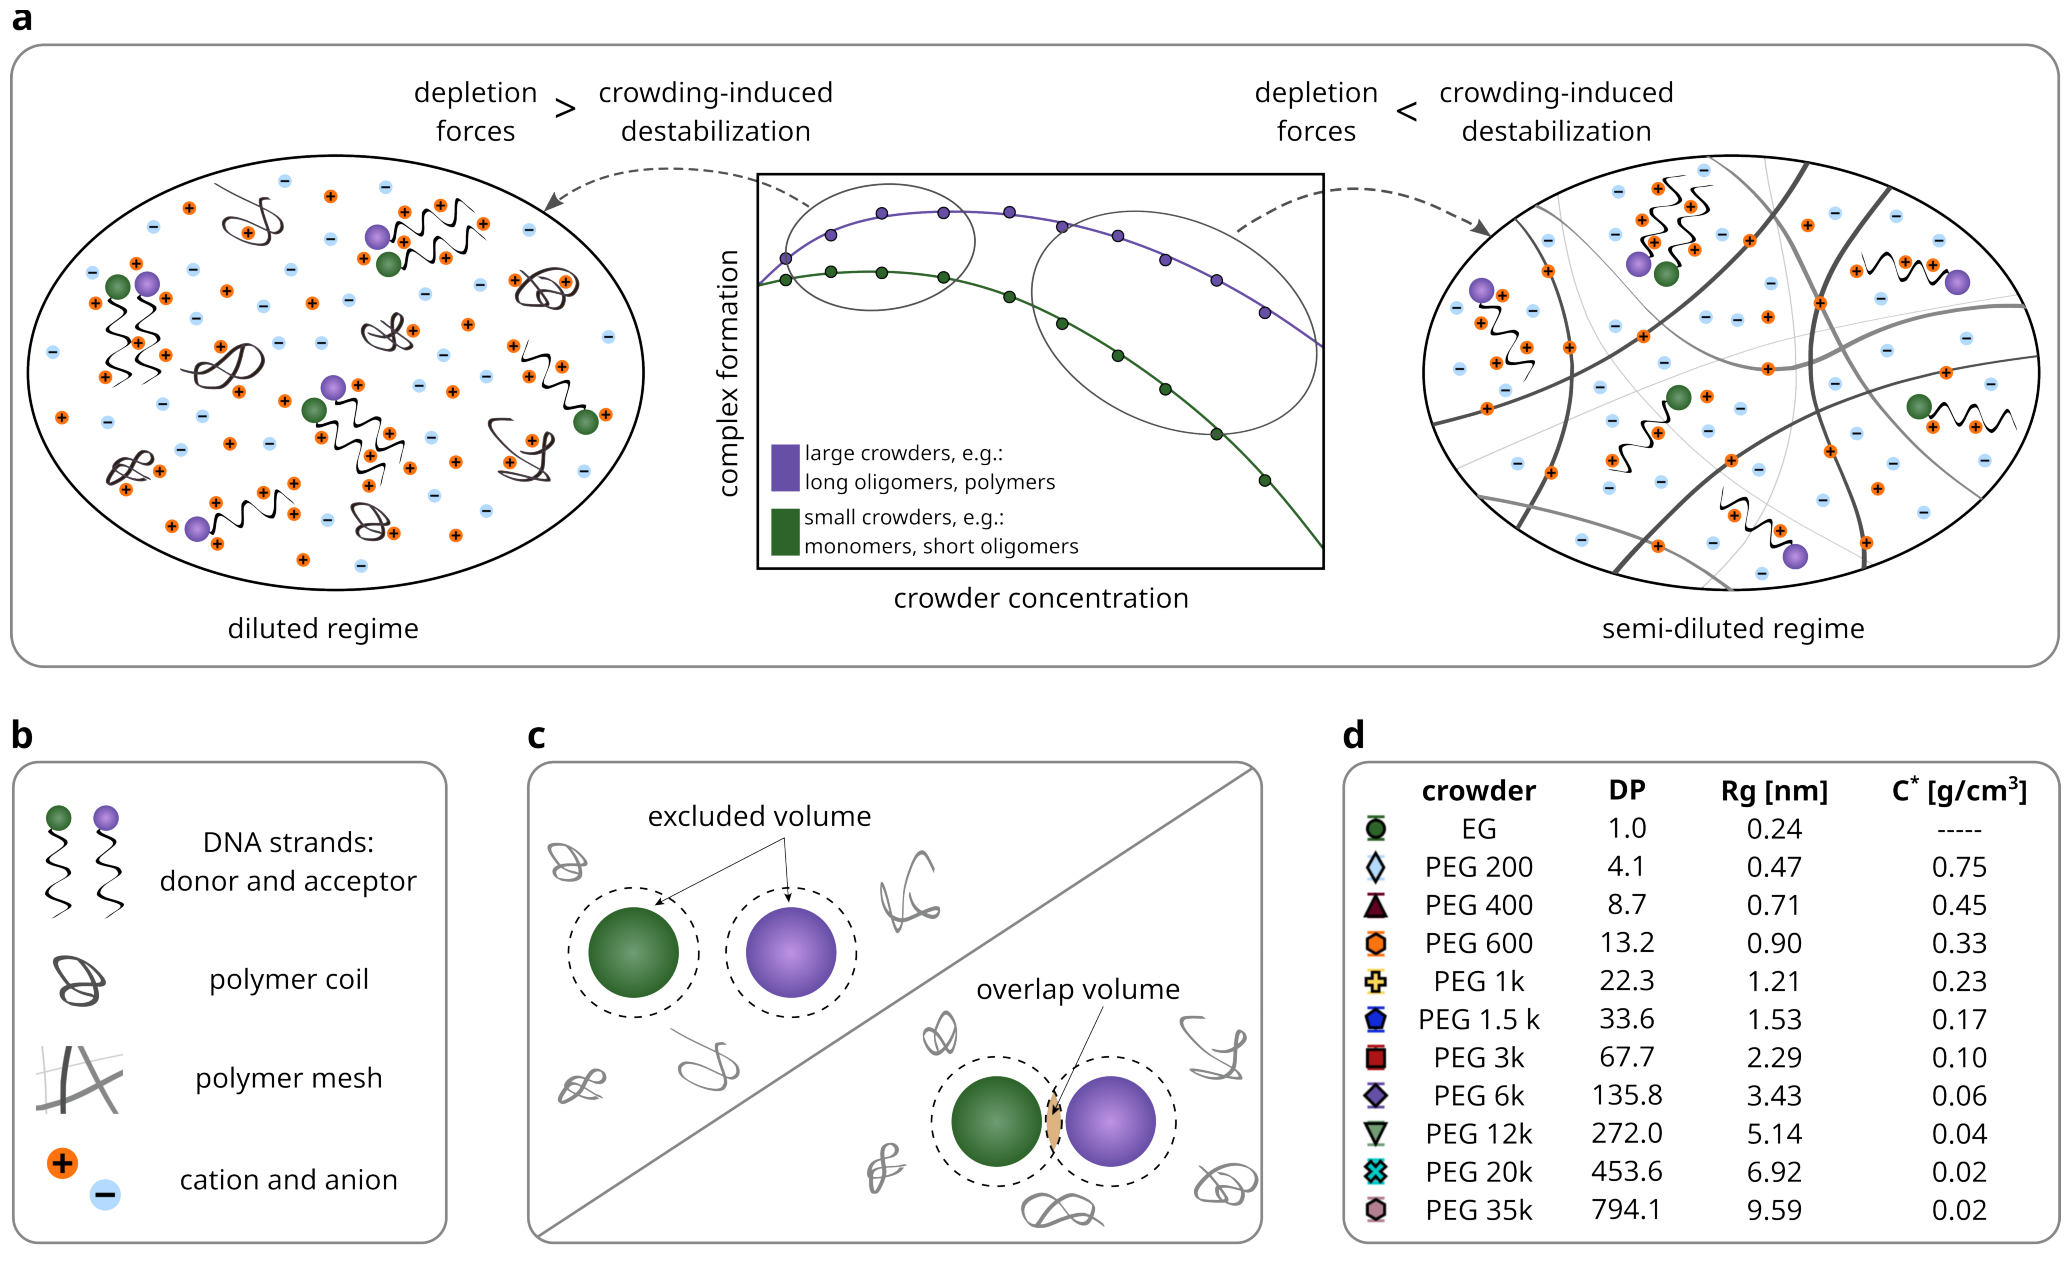

In [8]:
# Figure 1: hand-drawn artwork, converted from SVG to PDF without rasterizing
FIGURE_1_SVG = figure_dir / 'figure1.svg'

export_svg_pdf(FIGURE_1_SVG)

preview = imread(str(render_svg(FIGURE_1_SVG)))
height, width = preview.shape[:2]

fig, ax = plt.subplots(figsize=(3 * PANEL_W, 3 * PANEL_W * height / width))
ax.set_axis_off()
ax.imshow(preview)
fig.tight_layout()
plt.show()

## Figure 2 - Crowding effects on DNA-DNA hybridization

In [9]:
def panel_2a(ax):
    """Figure 2a - representative K fits for EG and PEG 35k at 25 wt.%

    Panel body taken from combined_plots.ipynb, cell 10.
    """
    plt.sca(ax)

    # selected K fits
    # errors in the plot are model-based propagated uncertainties
    # Define the desired datasets
    target_datasets = {('EGly', 25), ('PEG35000', 25)}

    # Set up a single figure for both plots

    # Loop through files
    directory = project_root / 'source_data' / 'MacromoleculeEquilibria_Crowding' / 'our_raw_results' / 'DNA-DNA_countrate_vs_crowder_concentration'
    for filename in os.listdir(directory):
        if not filename.endswith('.csv'):
            continue

        crowder_name, wt_percent, base_name = extract_name_and_value_from_a_file(filename)
        if not crowder_name or crowder_name not in styles:
            continue

        if (crowder_name, wt_percent) not in target_datasets:
            continue

        df = pd.read_csv(directory / filename)
        RI = wt_percent * df_RI.at[crowder_name, 'slope'] + df_RI.at[crowder_name, 'intercept']
        z_correction = RI / 1.333  # RI_water

        # Constants
        C_Don = compute_effective_donor_concentration(
        wt_percent,
        C_nominal=1e-8)
        alfa = df['a'][0]
        gamma = alfa * df['y'][0]
        v0 = 6.02e23 * 1e-16 * 10 * df['Vef_[fl]'][0] * z_correction
        n = 1

        x = df['ratio'] * C_Don
        y = df['value']
        xx = np.linspace(0, 1e-7, 500)

        # Fitting function
        K_fitting = make_K_fitting(alfa, gamma, v0, n)

        model = Model(K_fitting)
        model.set_param_hint('K', value=1e6, min=1e2, max=5e13)
        model.set_param_hint('D', value=1e-8, min=1.1e-9, max=2e-8)
        result = model.fit(y, x=x)

        fitK = result.params['K'].value
        fitKerr = result.params['K'].stderr
        fitD = result.params['D'].value

        # Use model-derived uncertainty
        y_model_uncertainty = result.eval_uncertainty(x=x)

        # Plot on shared axes
        style = styles[crowder_name]
        plt.errorbar(x*10**9, y, yerr=y_model_uncertainty, fmt=style['marker'], ms=style['ms'],
                     color=style['color'], mec=style['mec'], label=f'{style["label"]} {wt_percent:.1f} wt.% data',
                     elinewidth=1.2, capsize=3)

        plt.plot(xx*10**9, K_fitting(xx, fitK, fitD),
                 label=fr'{style["label"]} {wt_percent:.1f} wt.% fit: $K = ({fitK:.1e} \pm {fitKerr:.1e})$ M$^{{-1}}$',
                 color=style['color'], linestyle='--', lw=2)

    # Finalize combined plot
    plt.xlabel(r'$C_{DNA}$ (acceptor) [nM]', fontsize=17)
    plt.ylabel('donor count rate [cps]', fontsize=17)
    plt.title(r'$K$ fits for EG and PEG 35k at 25 wt.%', fontsize=20)
    plt.legend(fontsize=11, frameon=True)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

In [10]:
def panel_2b(ax):
    """Figure 2b - equilibrium association constants vs crowder concentration

    Panel body taken from combined_plots.ipynb, cell 13.
    """
    plt.sca(ax)

    # K vs crowder wt.%
    experimental_data = data.copy()

    # Create plot

    # --- Plot buffer point ---
    buffer_style = styles['buffer']
    plt.errorbar(buffer_style['x'], buffer_style['y'], yerr=buffer_style['yerr'],
                 color=buffer_style['color'], marker=buffer_style['marker'],
                 mec=buffer_style['mec'], linestyle='none', lw=1,
                 ms=buffer_style['ms'], elinewidth=1, capsize=3, capthick=1,
                 label=buffer_style['label'])

    # --- Plot data for all crowders ---
    for peg, style in styles.items():
        if peg == 'buffer':
            continue

        df = experimental_data[experimental_data['crowder'] == peg]
        if df.empty:
            continue

        x = df['crowder wt. [%]'].values
        y, y_err = uts.get_float_uncertainty(df['K_uf [M]'])

        plt.errorbar(x, y, yerr=y_err,
                     color=style['color'], marker=style['marker'],
                     mec=style['mec'], linestyle='none', lw=1, ms=style['ms'],
                     elinewidth=1, capsize=3, capthick=1,
                     label=style['label'])

    # --- Formatting ---
    plt.title('$K$ vs crowder concentration', fontsize=20)
    plt.xlabel('crowder concentration [wt.%]', fontsize=17)
    plt.ylabel(r'$K$ [M$^{-1}$]', fontsize=17)
    plt.axhline(buffer_style['y'], color='#868788', lw=1.5, linestyle='--')
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.yscale('log')
    plt.xlim(-3, 43)
    plt.legend(frameon=True, loc='lower left', fontsize=9)

In [11]:
def panel_2c(ax):
    """Figure 2c - crowder-induced change in hybridization free energy

    Panel body taken from combined_plots.ipynb, cell 14.
    """
    plt.sca(ax)

    # ΔG vs crowder wt.%
    experimental_data = data.copy()

    # Get buffer K
    K_buffer = styles['buffer']['y'][0]

    # Constants
    R = uts.R  # J/(mol*K)
    T = uts.T  # K

    # Create plot

    # --- Plot buffer point at ΔG = 0 ---
    buffer_style = styles['buffer']
    plt.errorbar(buffer_style['x'], [0], yerr=[0],
                 color=buffer_style['color'], marker=buffer_style['marker'],
                 mec=buffer_style['mec'], linestyle='none', lw=1,
                 ms=buffer_style['ms'], elinewidth=1, capsize=3, capthick=1,
                 label=buffer_style['label'])

    # --- Plot data for each crowder ---
    for peg, style in styles.items():
        if peg == 'buffer':
            continue

        df = experimental_data[experimental_data['crowder'] == peg]
        if df.empty:
            continue

        x = df['crowder wt. [%]'].values
        y, y_err = uts.get_float_uncertainty(df['K_uf [M]'])

        # Calculate ΔG [kJ/mol] relative to buffer
        deltaG = -R * T * (np.log(y) - np.log(K_buffer)) / 1000
        deltaG_err = (R * T * y_err / y) / 1000

        plt.errorbar(x, deltaG, yerr=deltaG_err,
                     color=style['color'], marker=style['marker'],
                     mec=style['mec'], linestyle='none', lw=1, ms=style['ms'],
                     elinewidth=1, capsize=3, capthick=1,
                     label=style['label'])

    # --- Formatting ---
    plt.title(r'$\Delta\Delta G$ vs crowder concentration', fontsize=20)
    plt.xlabel('crowder concentration [wt.%]', fontsize=17)
    plt.ylabel(r'$\Delta\Delta G$ [kJ/mol]', fontsize=17)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.axhline(0, color='#868788', lw=1.5, linestyle='--')
    plt.xlim(-3, 43)
    plt.legend(frameon=True, loc='upper left', fontsize=9)

In [12]:
def panel_2d(ax):
    """Figure 2d - phenomenological molecular-crowding fits for EG and PEG 35k

    Panel body taken from combined_plots.ipynb, cell 17.
    """
    plt.sca(ax)

    # molecular crowding fits for selected crowders
    # legends are displayed with M units, but fits are for wt.%


    # Load data
    experimental_data = data.copy()

    # Crowders to include
    selected_crowders = ['EGly', 'PEG35000']

    # Create plot

    # --- Add buffer point ---
    buffer_style = styles['buffer']
    plt.errorbar(buffer_style['x'], buffer_style['y'], yerr=buffer_style['yerr'],
                 color=buffer_style['color'], marker=buffer_style['marker'],
                 mec=buffer_style['mec'], linestyle='none', lw=1,
                 ms=buffer_style['ms'], elinewidth=1, capsize=3, capthick=1)

    # --- Plot each selected crowder ---
    for peg in selected_crowders:
        style = styles[peg]

        # Filter and extract data
        df = experimental_data[experimental_data['crowder'] == peg]
        if df.empty:
            continue

        x = df['crowder wt. [%]'].values            # for plotting
        x_M = df['concentration [M]'].values         # for legend equation
        y, y_err = uts.get_float_uncertainty(df['K_uf [M]'])
        log_y = np.log(y)

        # Fit in wt.% for plotting
        try:
            popt, pcov = curve_fit(quad_model, x, log_y)
            a0, a1, a2 = popt
            a0_err, a1_err, a2_err = np.sqrt(np.diag(pcov))
        except Exception as e:
            print(f"Fit failed in wt.% for {peg}: {e}")
            continue

        # Fit in [M] for display in legend
        try:
            popt_M, _ = curve_fit(quad_model, x_M, log_y)
            a0_M, a1_M, a2_M = popt_M
        except Exception as e:
            print(f"Fit in M failed for {peg}: {e}")
            a0_M, a1_M, a2_M = np.nan, np.nan, np.nan

        # Plot data points
        plt.errorbar(x, y, yerr=y_err,
                     color=style['color'], marker=style['marker'],
                     mec=style['mec'], linestyle='none', lw=1, ms=style['ms'],
                     elinewidth=1, capsize=3, capthick=1)

        # Fit curve and uncertainty band (in wt.%)
        x_parabola = np.linspace(0, 43, 200)
        lnK_fit = a0 + a1 * x_parabola + a2 * x_parabola**2
        lnK_err = np.sqrt(
            a0_err**2 +
            (x_parabola**2) * a1_err**2 +
            (x_parabola**4) * a2_err**2
        )

        y_fit = np.exp(lnK_fit)
        y_upper = np.exp(lnK_fit + lnK_err)
        y_lower = np.exp(lnK_fit - lnK_err)

        # Plot fit line and uncertainty band
        plt.plot(x_parabola, y_fit, color=style['color'], linestyle='--', lw=1.5,
                 label=f'{style["label"]} fit\nln$K$ = {a0_M:.1f} + {a1_M:.1f}x [M$^{{-1}}$] + {a2_M:.1f}x$^2$ [M$^{{-2}}$]')
        plt.fill_between(x_parabola, y_lower, y_upper, color=style['color'], alpha=0.2,
                         label=f'{style["label"]} uncertainty band')

    # --- Final formatting ---
    plt.title('Molecular crowding fits for EG and PEG 35k', fontsize=20)
    plt.xlabel('crowder concentration [wt.%]', fontsize=17)
    plt.ylabel(r'$K$ [M$^{-1}$]', fontsize=17)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.yscale('log')
    plt.xlim(-3, 43)
    plt.legend(frameon=True, loc='lower left', fontsize=11)

In [13]:
def panel_2e(ax):
    """Figure 2e - fit coefficients a1 and a2 vs degree of polymerization

    Panel body taken from combined_plots.ipynb, cell 20.
    """
    plt.sca(ax)

    # a1 and a2 values from molecular crowding fits

    # Load data
    experimental_data = data.copy()

    # Storage
    monomer_numbers = []
    a1_vals, a1_errs = [], []
    a2_vals, a2_errs = [], []

    # Loop through crowders
    for peg, style in styles.items():
        if peg == 'buffer':
            continue

        df = experimental_data[experimental_data['crowder'] == peg]
        if df.empty or 'No_mono' not in df.columns:
            continue

        x = df['concentration [M]'].values
        y, _ = uts.get_float_uncertainty(df['K_uf [M]'])
        log_y = np.log(y)

        try:
            popt, pcov = curve_fit(quad_model, x, log_y)
            a1, a2 = popt[1], popt[2]
            a1_err, a2_err = np.sqrt(pcov[1, 1]), np.sqrt(pcov[2, 2])

            monomer_numbers.append(df['No_mono'].iloc[0])
            a1_vals.append(a1)
            a1_errs.append(a1_err)
            a2_vals.append(a2)
            a2_errs.append(a2_err)
        except Exception as e:
            print(f"Fit failed for {peg}: {e}")
            continue

    # --- Plotting ---
    ax1 = ax

    # a1 on left y-axis
    ax1.errorbar(monomer_numbers, a1_vals, yerr=a1_errs, fmt='.', capsize=4, ms=12,
                 color='#2d642a', ecolor='#2d642a', mec='#000000', elinewidth=1.2, capthick=1,
                 label=r'$a_1$', zorder=3)
    ax1.set_ylabel(r'$a_1$ [M$^{-1}$]', fontsize=17, color='#2d642a')
    ax1.set_xlabel('degree of polymerization', fontsize=16)
    ax1.tick_params(axis='y', labelcolor='#2d642a', labelsize=12)
    ax1.tick_params(axis='x', labelsize=12)
    ax1.set_xscale('log')

    # a2 on right y-axis
    ax2 = ax1.twinx()
    ax2.errorbar(monomer_numbers, a2_vals, yerr=a2_errs, fmt='D', capsize=4, ms=5.5,
                 color='#674ea7', ecolor='#674ea7', mec='#000000', elinewidth=1.2, capthick=1,
                 label=r'$a_2$', zorder=3)
    ax2.set_ylabel(r'$a_2$ [M$^{-2}$]', fontsize=16, color='#674ea7')
    ax2.tick_params(axis='y', labelcolor='#674ea7', labelsize=12)
    ax2.yaxis.set_major_formatter(ScalarFormatter(useMathText=True))
    ax2.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

    # Combine legends
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='center left', fontsize=11, frameon=True)

    # Final formatting
    ax1.set_title(r'$a_1$ and $a_2$ coefficients vs polymer length', fontsize=18)

In [14]:
def panel_2f(ax):
    """Figure 2f - reduced concentration at maximum stabilization vs radius of gyration

    Panel body taken from combined_plots.ipynb, cell 36.
    """
    plt.sca(ax)

    # Reduced concentration at maximum duplex stabilization vs radius of gyration

    # Work on a copy of the permanent master dataframe.
    plot_data = data.copy()

    # Apply the original concentration filter
    plot_data = plot_data[
        plot_data['crowder wt. [%]'] < 50
    ].copy()

    # Verify that the required columns are present
    required_columns = [
        'crowder',
        'Rg_[nm]',
        'a1_exp',
        'a2_exp',
        'c*_[M]' 
    ]

    missing_columns = [
        column for column in required_columns
        if column not in plot_data.columns
    ]

    if missing_columns:
        raise KeyError(
            f'Missing required columns: {missing_columns}'
        )

    # Position of the quadratic minimum:
    # c_min/c* = -a1 / (2 a2 c*)
    plot_data['deltaG_minima'] = (
        -plot_data['a1_exp']
        / (2 * plot_data['a2_exp'])
        / plot_data['c*_[M]']
    )



    for crowder, style in styles.items():

        if crowder in {'buffer', 'EGly'}:
            continue

        crowder_df = plot_data[
            plot_data['crowder'] == crowder
        ].copy()

        crowder_df = crowder_df.dropna(
            subset=[
                'Rg_[nm]',
                'a1_exp',
                'a2_exp',
                'c*_[M]',
                'deltaG_minima'
            ]
        )

        if crowder_df.empty:
            continue

        # These values are repeated for each concentration,
        # so use one row per crowder
        row = crowder_df.iloc[0]

        # Radius of gyration
        x_value = float(row['Rg_[nm]'])

        if (
            'Rg_err_[nm]' in crowder_df.columns
            and pd.notna(row['Rg_err_[nm]'])
        ):
            x_error = float(row['Rg_err_[nm]'])
        else:
            x_error = None

        # Extract nominal minimum position and propagated uncertainty
        y_value = float(
            unp.nominal_values(row['deltaG_minima'])
        )
        y_error = float(
            unp.std_devs(row['deltaG_minima'])
        )

        if (
            not np.isfinite(x_value)
            or not np.isfinite(y_value)
            or not np.isfinite(y_error)
        ):
            continue

        plt.errorbar(
            x_value,
            y_value,
            xerr=x_error,
            yerr=y_error,
            color=style['color'],
            marker=style['marker'],
            mfc=style['color'],
            mec=style['mec'],
            linestyle='none',
            lw=1,
            ms=style['ms'],
            elinewidth=1,
            capsize=3,
            capthick=1,
            label=style['label']
        )

    plt.title(
        'Position of $\Delta\Delta G_{minimum}$ vs $R_g$',
        fontsize=20
    )
    plt.xlabel(
        r'$R_g$ [nm]',
        fontsize=17
    )
    plt.ylabel(
        r'concentration at $\Delta\Delta G_{minimum}$ [$c/c^*$]',
        fontsize=17
    )

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.axhline(
        y=1,
        color='black',
        linestyle='--',
        lw=1
    )

    plt.legend(
        frameon=True,
        loc='upper left',
        fontsize=9
    )

<>:118: SyntaxWarning: invalid escape sequence '\D'
<>:118: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_245228/3492496038.py:118: SyntaxWarning: invalid escape sequence '\D'
  'Position of $\Delta\Delta G_{minimum}$ vs $R_g$',


saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/figure2.png and .pdf


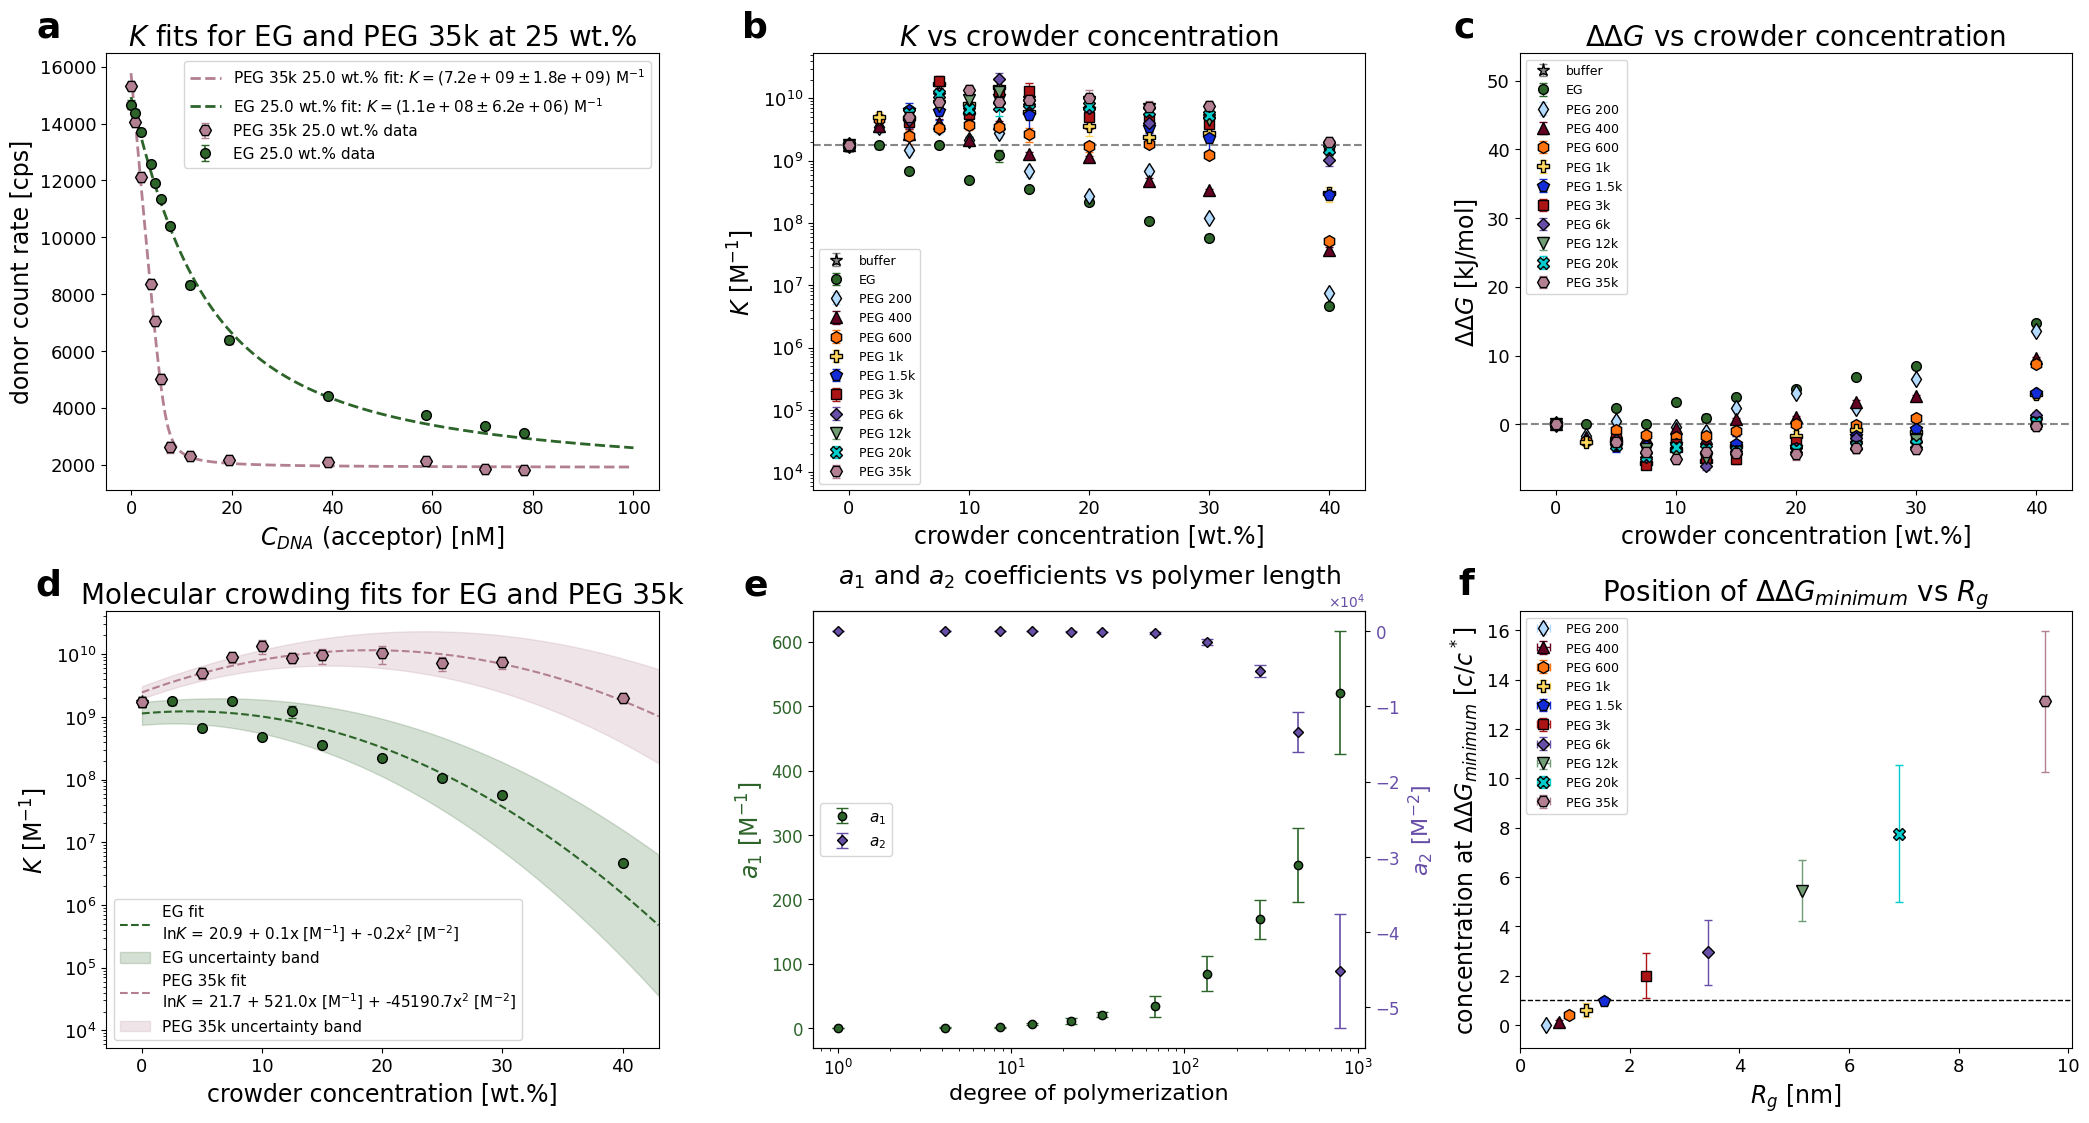

In [15]:
# Figure 2: panels a-f on a 2 x 3 grid
fig, axes = plt.subplots(2, 3, figsize=(3 * PANEL_W, 2 * PANEL_H))

panels = [
    ('a', panel_2a), ('b', panel_2b), ('c', panel_2c),
    ('d', panel_2d), ('e', panel_2e), ('f', panel_2f),
]

for ax, (letter, draw_panel) in zip(axes.flat, panels):
    draw_panel(ax)

fig.tight_layout()

for ax, (letter, _) in zip(axes.flat, panels):
    label_panel(ax, letter)
save_figure(fig, 'figure2')
plt.show()

## Figure 3 - PEG-Na+ coupling

Panel a is the schematic of sodium coupling to the PEG chains. It is not
produced from data: the artwork was cut out of `helping_files/new_Adam/molecular_crowding.svg`
and is kept as `publication_plots/figure3a.svg`.

In [16]:
def panel_3b(ax):
    """Figure 3b - representative DOSY signal-attenuation analysis

    Panel body taken from combined_plots.ipynb, cell 23.
    """
    plt.sca(ax)

    # NMR DOSY diffusion coefficients for PEG 400
    # Stejskal-Tanner: I = I0 * exp(-D * (2 pi gamma delta g)^2 * (Delta - delta/3))
    # gamma in Hz/G, g in G/cm, delta and Delta in s
    # -> (2 pi gamma delta g)^2 is in 1/cm^2, hence the 1e4 factor to get D in m^2/s

    dosy_dir = project_root / 'source_data' / 'NMRDosy'

    # Each nucleus is plotted with the style of the quantity it reports:
    # the 1H signal follows the crowder (PEG 400), the 23Na signal the sodium (buffer) style.
    dosy_datasets = {
        '1H': {
            'file': 'PEG400_1H.csv',
            'delta_[s]': 0.0020,
            'Delta_[s]': 0.197033,
            'gamma_[Hz/G]': 4257.7,
            'style': styles['PEG400'],
            'label': r'PEG 400, $^{1}$H',
        },
        '23Na': {
            'file': 'PEG400_23NA.csv',
            'delta_[s]': 0.0050,
            'Delta_[s]': 0.033033,
            'gamma_[Hz/G]': 1126.0,
            'style': styles['buffer'],
            'label': r'Na$^{+}$ in PEG 400, $^{23}$Na',
        },
    }


    def stejskal_tanner_model(delta, Delta, gamma):
        """Return the Stejskal-Tanner decay I(g) and its diffusion weighting b/g^2.

        D is fitted in units of 1e-9 m^2/s, which keeps the optimizer well scaled.
        """
        b_over_g2 = (2 * np.pi * gamma * delta) ** 2 * (Delta - delta / 3) * 1e4

        def model(g, I0, D):
            return I0 * np.exp(-D * 1e-9 * b_over_g2 * g ** 2)

        return model, b_over_g2



    g_max = 0
    for nucleus, params in dosy_datasets.items():
        df = pd.read_csv(dosy_dir / params['file'])
        g = df['G_Gauss_per_cm'].astype(float).values
        intensity = df['I'].astype(float).values
        g_max = max(g_max, g.max())

        model, _ = stejskal_tanner_model(params['delta_[s]'], params['Delta_[s]'], params['gamma_[Hz/G]'])
        popt, pcov = curve_fit(model, g, intensity, p0=[1.0, 1.0])
        perr = np.sqrt(np.diag(pcov))
        D, D_err = popt[1], perr[1]

        print(f"{nucleus}: I0 = {popt[0]:.4f} +/- {perr[0]:.4f}, "
              f"D = ({D:.3f} +/- {D_err:.3f})e-09 m^2/s")

        style = params['style']

        # Fit curve
        g_fit = np.linspace(0, g_max * 1.02, 300)
        plt.plot(g_fit, model(g_fit, *popt), color=style['color'], linestyle='--', lw=1.5)

        # Data
        plt.plot(g, intensity,
                 color=style['color'], marker=style['marker'],
                 mfc=style['color'], mec=style['mec'],
                 linestyle='none', lw=1, ms=style['ms'],
                 label=f"{params['label']}, $D$ = ({D:.2f} $\\pm$ {D_err:.2f})$\\cdot 10^{{-9}}$ m$^2$/s")

    # --- Formatting ---
    plt.title('DOSY signal decay for PEG 400', fontsize=20)
    plt.xlabel('gradient strength [G/cm]', fontsize=17)
    plt.ylabel(r'normalized intensity $I/I_{0}$', fontsize=17)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.xlim(0, g_max * 1.02)
    plt.legend(frameon=True, loc='upper right', fontsize=10)

In [17]:
def panel_3c(ax):
    """Figure 3c - crowder self-diffusion coefficients vs crowder concentration

    Panel body taken from combined_plots.ipynb, cell 25.
    """
    plt.sca(ax)

    # D_crowder vs crowder wt.%
    crowders_df = equillibrium_constants.analyzed_data.copy()

    # Crowders to exclude
    excluded = {'Dextran6000', 'Dextran70000', 'Ficoll400000'}

    # Create the plot

    # Loop through crowders
    for name, style in styles.items():
        if name in excluded:
            continue

        df = crowders_df[crowders_df['crowder'] == name].copy()
        if df.empty:
            continue

        if {'wt_%', 'D_crowder_[um2/s]'}.issubset(df.columns):

            x_all = df['wt_%'].astype(float).values
            y_all = df['D_crowder_[um2/s]'].astype(float).values

            if 'D_crowder_err_[um2/s]' in df.columns:
                y_err_all = df['D_crowder_err_[um2/s]'].astype(float).values
            elif 'D_crowder_uf_[um2/s]' in df.columns:
                _, y_err_all = uts.get_float_uncertainty(df['D_crowder_uf_[um2/s]'])
            else:
                continue

            # Skip 0% row for fitting and plotting
            x = x_all[1:]
            y = y_all[1:]
            y_err = y_err_all[1:]
            if len(x) < 3:
                continue

            # Fit
            a, b, c, r_squared = uts.exponential_fit_with_r_squared(x, y)
            x_fit = np.linspace(0, 19, 200)
            y_fit = uts.exponential_model(x_fit, a, b, c)

            # Plot fit
            plt.plot(x_fit, y_fit, color=style['color'], linestyle='--', lw=1.5)

            # Plot data
            plt.errorbar(x, y, yerr=y_err,
                         color=style['color'], marker=style['marker'],
                         mfc=style['color'], mec=style['mec'],
                         linestyle='none', lw=1, ms=style['ms'],
                         elinewidth=1, capsize=3, capthick=1,
                         label=f"{style['label']}, R$^2$ = {r_squared:.3f}")

    # Final touches
    plt.title('$D_{crowder}$ vs crowder wt.%', fontsize=20)
    plt.xlabel('crowder wt.%', fontsize=17)
    plt.ylabel('$D_{crowder}$ [um$^2$/s]', fontsize=17)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.xlim(-1, 19)
    plt.legend(frameon=True, loc='upper right', fontsize=9)

In [18]:
def panel_3d(ax):
    """Figure 3d - observed sodium self-diffusion coefficients vs crowder concentration

    Panel body taken from combined_plots.ipynb, cell 24, with the linear fits
    and their R^2 legend entries removed.
    """
    plt.sca(ax)

    # D_Na+ vs crowder wt.%
    crowders_df = equillibrium_constants.analyzed_data.copy()

    # Crowders to exclude
    excluded = {'Dextran6000', 'Dextran70000', 'Ficoll400000'}

    # Create plot

    # Loop through crowders and plot D_Na
    for name, style in styles.items():
        if name in excluded:
            continue

        df = crowders_df[crowders_df['crowder'] == name].copy()
        if df.empty:
            continue

        if {'wt_%', 'D_Na_[um2/s]'}.issubset(df.columns):
            x = df['wt_%'].astype(float).values
            y = df['D_Na_[um2/s]'].astype(float).values

            if 'D_Na_err_[um2/s]' in df.columns:
                y_err = df['D_Na_err_[um2/s]'].astype(float).values
            elif 'D_Na_uf_[um2/s]' in df.columns:
                _, y_err = uts.get_float_uncertainty(df['D_Na_uf_[um2/s]'])
            else:
                continue

            # Plot data (excluding 0%), without the linear fits of the single plot
            plt.errorbar(x[1:], y[1:], yerr=y_err[1:],
                         color=style['color'], marker=style['marker'],
                         mfc=style['color'], mec=style['mec'],
                         linestyle='none', lw=1, ms=style['ms'],
                         elinewidth=1, capsize=3, capthick=1,
                         label=style['label'])

    # --- Explicitly add buffer point at (0, 1425.622636 +/- 57.95748743) ---
    plt.errorbar([0], [1425.622636], yerr=[57.95748743],
                 color=styles['buffer']['color'], marker=styles['buffer']['marker'],
                 mfc=styles['buffer']['color'], mec=styles['buffer']['mec'],
                 linestyle='none', lw=1, ms=styles['buffer']['ms'],
                 elinewidth=1, capsize=3, capthick=1,
                 label=styles['buffer']['label'])

    # Final formatting
    plt.title('$D_{Na^{+}}$ vs crowder wt.%', fontsize=20)
    plt.xlabel('crowder wt.%', fontsize=17)
    plt.ylabel('$D_{Na^{+}}$ [um$^2$/s]', fontsize=17)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.xlim(-1, 19)
    plt.ylim(380, 1550)
    plt.legend(frameon=True, loc='lower left', fontsize=9)

In [19]:
def panel_3e(ax):
    """Figure 3e - measured vs nanoviscosity-predicted sodium diffusion for PEG 35k

    Panel body taken from combined_plots.ipynb, cell 31.
    """
    plt.sca(ax)

    # nanoviscosity effect for PEG 35k
    buffer_style = styles['buffer']
    crowders_df = all_data.SodiumCrowderComplexationObj.analyzed_data.copy()

    crowder = 'PEG35000'
    crowder_df = crowders_df[crowders_df['crowder'] == crowder].copy()

    if not crowder_df.empty and 'D_Na_uf_[um2/s]' in crowder_df.columns:
        measured, measured_err = uts.get_float_uncertainty(crowder_df['D_Na_uf_[um2/s]'])
        D_viscosity = crowder_df['D_Na_[um2/s] corr']

        style = styles.get(crowder, buffer_style)


        plt.errorbar(crowder_df['wt_%'], measured, yerr=measured_err,
                     color=style['color'], marker=style['marker'],
                     mec=style['mec'], linestyle='none', lw=1, ms=style['ms'],
                     elinewidth=1, capsize=3, capthick=1,
                     label='$D_{Na^{+}}$ measured')

        plt.plot(crowder_df['wt_%'], D_viscosity,
                 color=buffer_style['color'], marker=buffer_style['marker'],
                 mec=buffer_style['mec'], linestyle='none', lw=1, ms=buffer_style['ms'],
                 label=r'nanoviscosity effect')

        plt.title(f'nanoviscosity effect for {style["label"]}', fontsize=20)
        plt.xlabel('crowder wt.%', fontsize=17)
        plt.ylabel('$D_{Na^{+}}$ [um$^2$/s]', fontsize=17)
        plt.xticks(fontsize=13)
        plt.yticks(fontsize=13)
        # plt.ylim(420, 1550)
        plt.legend(frameon=True, loc='lower left', fontsize=11)

In [20]:
def panel_3f(ax):
    """Figure 3f - representative fits of the coupling parameter beta*n

    Panel body taken from combined_plots.ipynb, cell 30.
    """
    plt.sca(ax)

    # Selected βn fits for EG and PEG 35k



    def model_for_fit(x, D_Na, D_crowder, beta_n):
        """
        Sodium diffusion model.

        x          : crowder concentration
        D_Na       : concentration-dependent corrected free-Na+ diffusivity
        D_crowder  : crowder diffusivity
        beta_n     : fitted nβ
        """
        return (
            D_Na + D_crowder * beta_n * x
        ) / (
            1 + beta_n * x
        )


    # Data object already created earlier in the notebook
    crowders_df = (
        all_data
        .SodiumCrowderComplexationObj
        .analyzed_data
        .copy()
    )

    selected_crowders = ['EGly', 'PEG35000']

    # Same figure size as the other plots in the notebook


    for crowder in selected_crowders:

        style = styles[crowder]

        # Select the current crowder
        crowder_data = crowders_df.loc[
            crowders_df['crowder'] == crowder
        ].copy()

        # Remove the buffer row before every fit and interpolation
        crowder_data = crowder_data.loc[
            (crowder_data['concentration [M]'].astype(float) > 0)
            & (crowder_data['wt_%'].astype(float) > 0)
        ].copy()

        crowder_data = crowder_data.sort_values('wt_%')

        if crowder_data.empty:
            continue

        # Crowder concentration in M
        x_data = (
            crowder_data['concentration [M]']
            .astype(float)
            .to_numpy()
        )

        # Crowder concentration in wt.%
        wt_data = (
            crowder_data['wt_%']
            .astype(float)
            .to_numpy()
        )

        # Experimentally measured sodium diffusion and uncertainty
        y_data, y_err = uts.get_float_uncertainty(
            crowder_data['D_Na_uf_[um2/s]']
        )

        y_data = np.asarray(y_data, dtype=float)
        y_err = np.asarray(y_err, dtype=float)

        # Concentration-dependent corrected free-sodium diffusivity
        D_Na = (
            crowder_data['D_Na_[um2/s] corr']
            .astype(float)
            .to_numpy()
        )

        # Crowder diffusion coefficient and uncertainty
        D_crowder, D_crowder_err = uts.get_float_uncertainty(
            crowder_data['D_crowder_uf_[um2/s]']
        )

        D_crowder = np.asarray(D_crowder, dtype=float)
        D_crowder_err = np.asarray(D_crowder_err, dtype=float)

        # Remove any invalid points
        valid = (
            np.isfinite(x_data)
            & np.isfinite(wt_data)
            & np.isfinite(y_data)
            & np.isfinite(y_err)
            & np.isfinite(D_Na)
            & np.isfinite(D_crowder)
            & (x_data > 0)
            & (wt_data > 0)
            & (y_err > 0)
        )

        x_data = x_data[valid]
        wt_data = wt_data[valid]
        y_data = y_data[valid]
        y_err = y_err[valid]
        D_Na = D_Na[valid]
        D_crowder = D_crowder[valid]
        D_crowder_err = D_crowder_err[valid]

        if len(x_data) < 3:
            continue

        # Ensure ascending wt.% order
        order = np.argsort(wt_data)

        x_data = x_data[order]
        wt_data = wt_data[order]
        y_data = y_data[order]
        y_err = y_err[order]
        D_Na = D_Na[order]
        D_crowder = D_crowder[order]
        D_crowder_err = D_crowder_err[order]

        # Initial βn value, used only as the starting estimate
        initial_beta_n = 1.0

        if 'n Beta [1/M]' in crowder_data.columns:
            stored_beta, _ = uts.get_float_uncertainty(
                crowder_data['n Beta [1/M]'].iloc[[0]]
            )

            stored_beta = float(stored_beta[0])

            if np.isfinite(stored_beta) and stored_beta > 0:
                initial_beta_n = stored_beta

        # Fit βn only to the positive-concentration crowder points
        def beta_fit_model(x, beta_n):
            return model_for_fit(
                x,
                D_Na,
                D_crowder,
                beta_n
            )

        popt, pcov = curve_fit(
            beta_fit_model,
            x_data,
            y_data,
            p0=[initial_beta_n],
            sigma=y_err,
            bounds=(0, np.inf),
            maxfev=100000
        )

        beta_n = float(popt[0])
        beta_n_err = float(np.sqrt(np.diag(pcov))[0])

        # Fit D_crowder only to positive-concentration crowder points
        a, b, c, _ = uts.exponential_fit_with_r_squared(
            wt_data,
            D_crowder
        )

        # Smooth plotting range starts at the first crowder point,
        # not at the buffer point
        wt_fit = np.linspace(
            wt_data.min(),
            wt_data.max(),
            500
        )

        # Convert the smooth wt.% range to molar concentration
        wt_per_molar = np.mean(
            wt_data / x_data
        )

        x_fit = wt_fit / wt_per_molar

        # Interpolate free-Na+ diffusivity using only crowder points
        D_Na_fit = np.interp(
            wt_fit,
            wt_data,
            D_Na
        )

        # Evaluate fitted crowder diffusivity
        D_crowder_fit = uts.exponential_model(
            wt_fit,
            a,
            b,
            c
        )

        # Calculate smooth βn model curve
        y_fit = model_for_fit(
            x_fit,
            D_Na_fit,
            D_crowder_fit,
            beta_n
        )

        # Fitted line without uncertainty bounds
        plt.plot(
            wt_fit,
            y_fit,
            color=style['color'],
            linestyle='--',
            lw=1.5,
            label=(
                rf'{style["label"]} fit: '
                rf'$\beta n = {beta_n:.2f} \pm {beta_n_err:.2f}$ '
                rf'M$^{{-1}}$'
            )
        )

        # Experimental crowder points
        plt.errorbar(
            wt_data,
            y_data,
            yerr=y_err,
            color=style['color'],
            marker=style['marker'],
            mfc=style['color'],
            mec=style['mec'],
            linestyle='none',
            lw=1,
            ms=style['ms'],
            elinewidth=1,
            capsize=3,
            capthick=1,
            label=f'{style["label"]} data'
        )


    # Display the buffer point once.
    # It was not used in any fit or interpolation above.
    buffer_style = styles['buffer']

    plt.errorbar(
        [0],
        [1425.622636],
        yerr=[57.95748743],
        color=buffer_style['color'],
        marker=buffer_style['marker'],
        mfc=buffer_style['color'],
        mec=buffer_style['mec'],
        linestyle='none',
        lw=1,
        ms=buffer_style['ms'],
        elinewidth=1,
        capsize=3,
        capthick=1,
        label=buffer_style['label']
    )


    # Formatting
    plt.title(
        r'$\beta n$ fit for EG and PEG 35k',
        fontsize=20
    )

    plt.xlabel(
        'crowder wt.%',
        fontsize=17
    )

    plt.ylabel(
        r'$D_w$ [$\mu$m$^2$/s]',
        fontsize=17
    )

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    maximum_wt = crowders_df.loc[
        crowders_df['crowder'].isin(selected_crowders),
        'wt_%'
    ].astype(float).max()

    plt.xlim(
        -0.5,
        maximum_wt + 1
    )

    plt.legend(
        frameon=True,
        loc='upper right',
        fontsize=11
    )

In [21]:
def panel_3g(ax):
    """Figure 3g - coupling parameter beta*n vs degree of polymerization

    Panel body taken from combined_plots.ipynb, cell 34.
    """
    plt.sca(ax)

    # nβ vs degree of polymerization (DP)
    crowders_df = equillibrium_constants.analyzed_data.copy()


    # Create plot

    x_fit_data = []
    y_fit_data = []

    # Plot one point for each crowder
    for name, style in styles.items():

        # There is no corresponding buffer point for this plot
        if name == 'buffer':
            continue

        crowder_df = crowders_df[
            crowders_df['crowder'] == name
        ].copy()

        crowder_df = crowder_df.dropna(
            subset=['No_mono', 'n Beta [1/M]']
        )

        if crowder_df.empty:
            continue

        # No_mono and nβ are repeated for different concentrations,
        # so only one value is required for each crowder
        x_value = float(crowder_df['No_mono'].iloc[0])

        y_value, y_error = uts.get_float_uncertainty(
            crowder_df['n Beta [1/M]'].iloc[[0]]
        )

        y_value = float(y_value[0])
        y_error = float(y_error[0])

        # Positive values are required for logarithmic axes
        if x_value <= 0 or y_value <= 0:
            continue

        x_fit_data.append(x_value)
        y_fit_data.append(y_value)

        # Plot the crowder using its individual style
        plt.errorbar(
            x_value,
            y_value,
            yerr=y_error,
            color=style['color'],
            marker=style['marker'],
            mfc=style['color'],
            mec=style['mec'],
            linestyle='none',
            lw=1,
            ms=style['ms'],
            elinewidth=1,
            capsize=3,
            capthick=1,
            label=style['label']
        )

    # Convert collected values to arrays
    x_fit_data = np.asarray(x_fit_data, dtype=float)
    y_fit_data = np.asarray(y_fit_data, dtype=float)

    # Global linear fit constrained through the origin:
    # nβ = a × DP
    a = np.dot(x_fit_data, y_fit_data) / np.dot(
        x_fit_data,
        x_fit_data
    )

    # Use logarithmically spaced coordinates because the x-axis is logarithmic
    x_line = np.logspace(
        np.log10(x_fit_data.min()),
        np.log10(x_fit_data.max()),
        200
    )

    # Plot global fit
    plt.plot(
        x_line,
        a * x_line,
        color='black',
        linestyle='--',
        lw=1.5,
        label=rf'fit: $\beta n = {a:.3g}\,\mathrm{{DP}}$'
    )

    # Final formatting
    plt.title(
        r'$\beta n$ vs degree of polymerization',
        fontsize=20
    )
    plt.xlabel('degree of polymerization', fontsize=17)
    plt.ylabel(r'$\beta n$ [M$^{-1}$]', fontsize=17)

    plt.xscale('log')
    plt.yscale('log')

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.legend(
        frameon=True,
        loc='best',
        fontsize=9
    )

1H: I0 = 1.0315 +/- 0.0114, D = (0.425 +/- 0.010)e-09 m^2/s
23Na: I0 = 0.9680 +/- 0.0180, D = (1.476 +/- 0.075)e-09 m^2/s


saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/figure3.png and .pdf


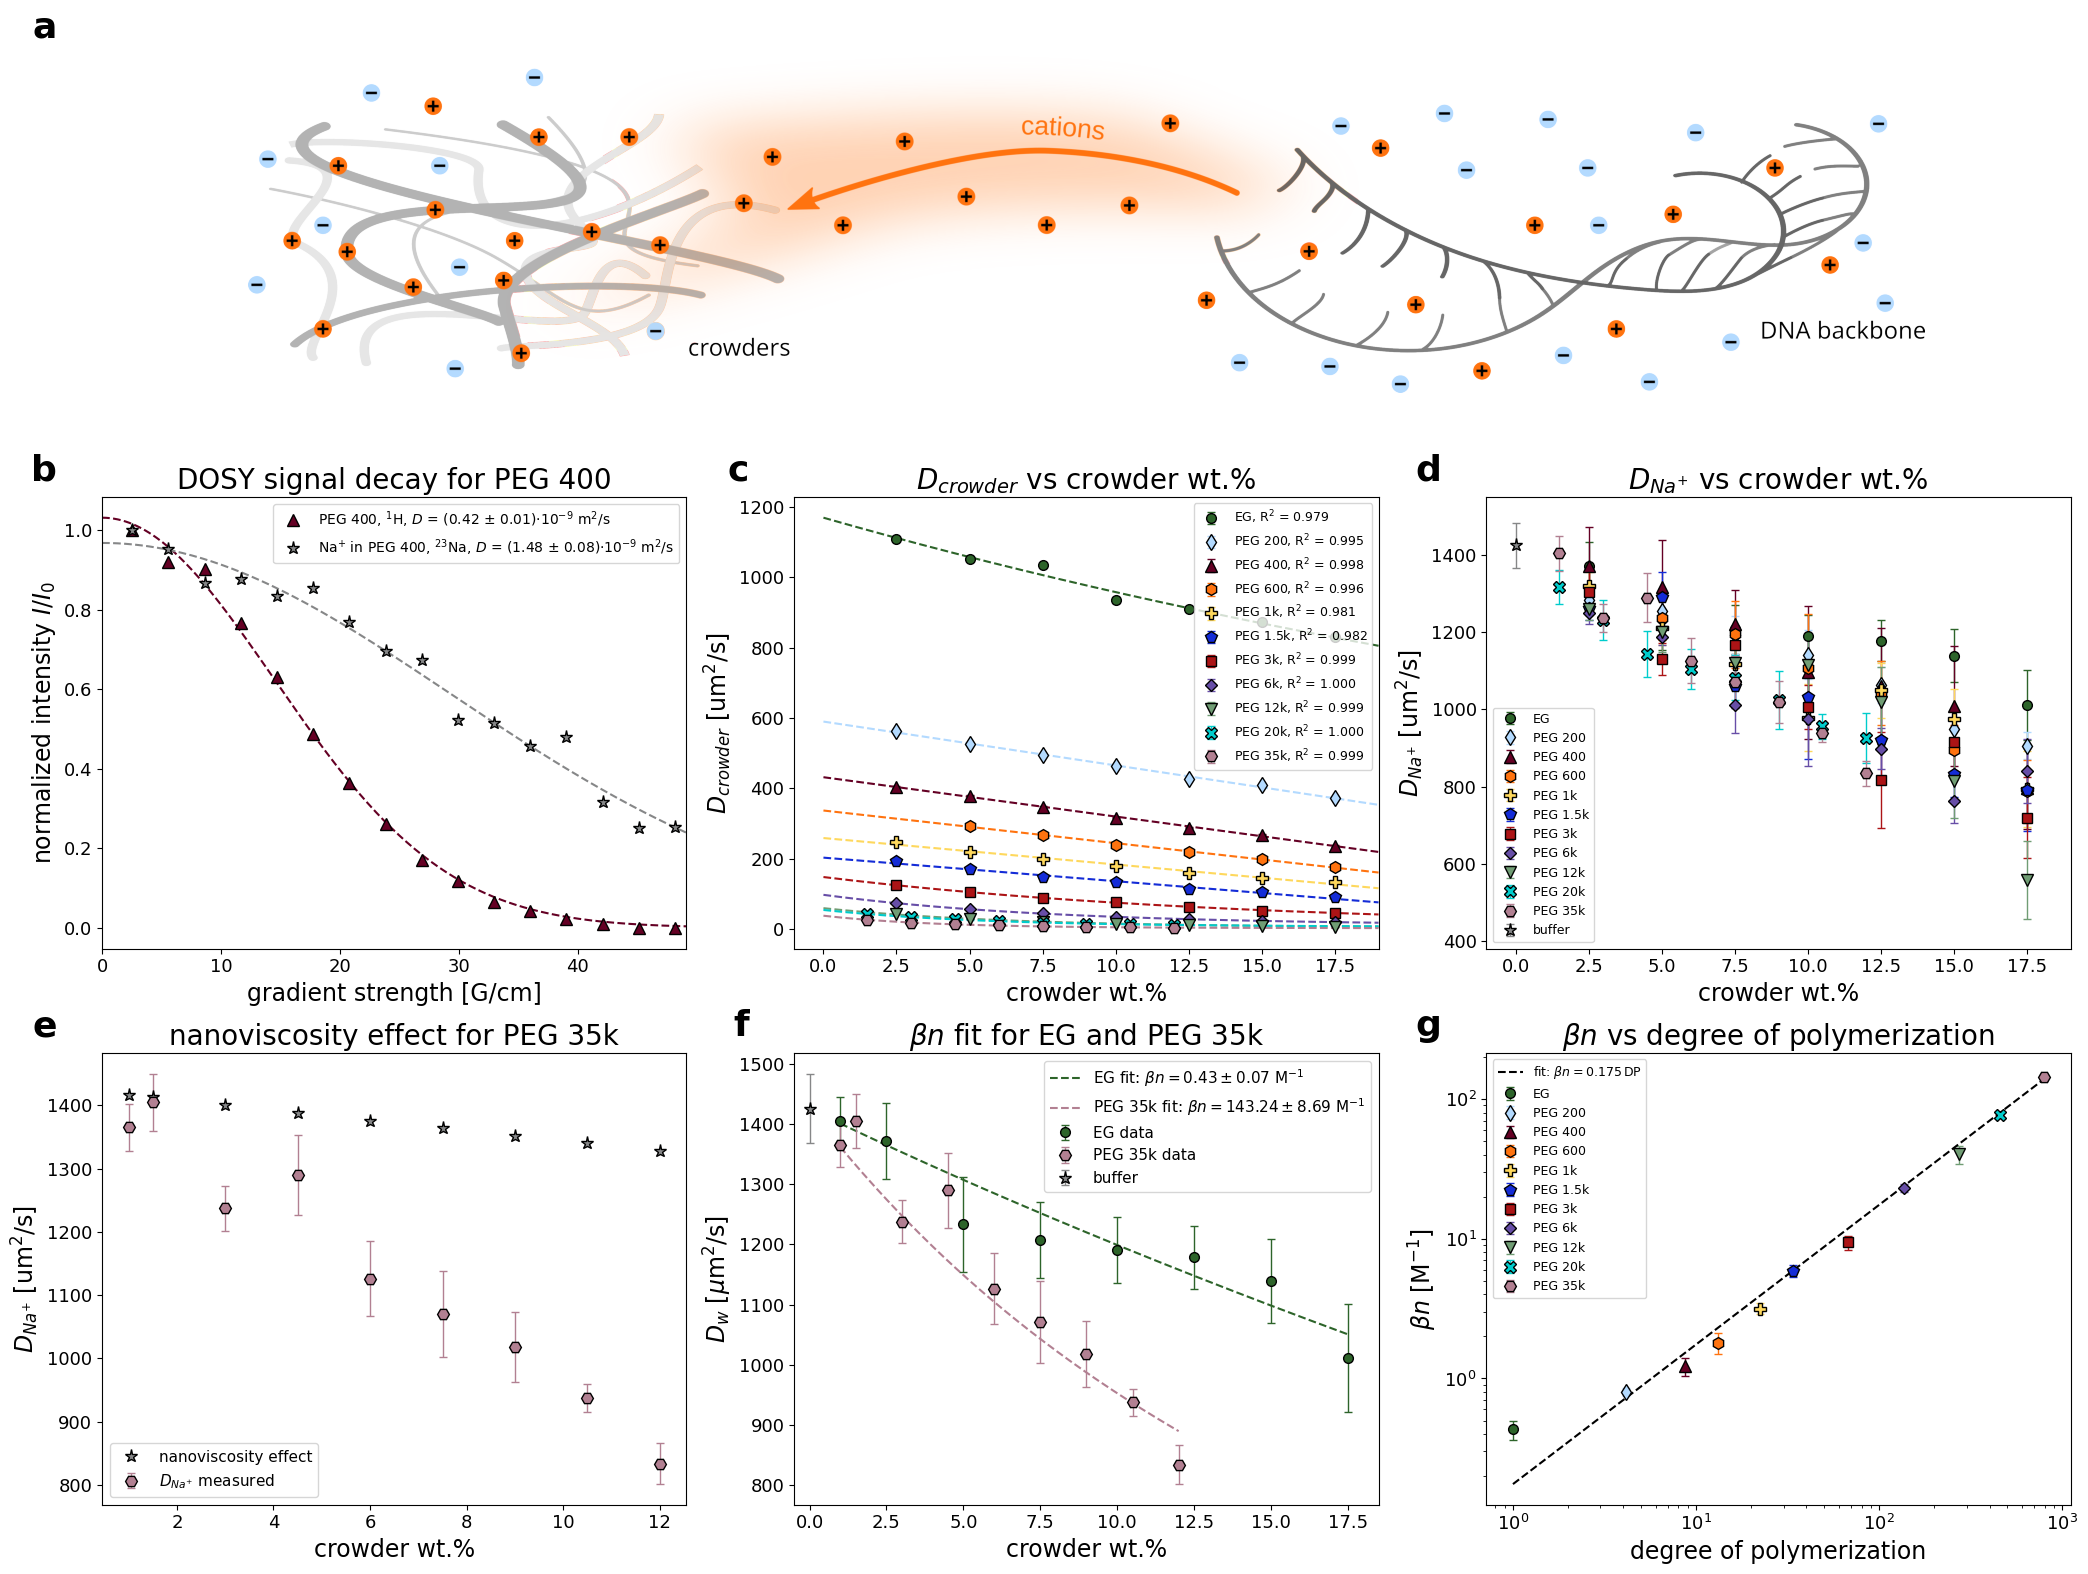

In [22]:
# Figure 3: wide schematic on top, then panels b-d and e-g
# Panel a is hand-drawn artwork cut out of helping_files/new_Adam/molecular_crowding.svg.
FIGURE_3A_SVG = figure_dir / 'figure3a.svg'


def panel_3a(ax):
    """Figure 3a - transient coupling of Na+ to the ether oxygens of PEG."""
    ax.set_axis_off()
    ax.imshow(imread(str(render_svg(FIGURE_3A_SVG))))


fig = plt.figure(figsize=(3 * PANEL_W, 2 * PANEL_H + 0.75 * PANEL_H))
grid = fig.add_gridspec(3, 3, height_ratios=[0.75, 1, 1])

ax_a = fig.add_subplot(grid[0, :])
panel_3a(ax_a)

panels = [
    ('b', panel_3b), ('c', panel_3c), ('d', panel_3d),
    ('e', panel_3e), ('f', panel_3f), ('g', panel_3g),
]

axes = []
for position, (letter, draw_panel) in zip([(1, 0), (1, 1), (1, 2),
                                           (2, 0), (2, 1), (2, 2)], panels):
    ax = fig.add_subplot(grid[position])
    draw_panel(ax)
    axes.append(ax)

fig.tight_layout()

# Panel a holds an image, so its axes is narrower than its grid slot; line its
# letter up with panel b instead of with its own left edge.
first_column_x = label_panel(axes[0], 'b')
label_panel(ax_a, 'a', x=first_column_x)

for ax, (letter, _) in zip(axes[1:], panels[1:]):
    label_panel(ax, letter)
save_figure(fig, 'figure3')
plt.show()

## Figure 4 - Electrostatic and depletion contributions

In [23]:
def panel_4a(ax):
    """Figure 4a - ionic-strength dependence of the hybridization free energy

    Panel body taken from combined_plots.ipynb, cell 39.
    """
    plt.sca(ax)

    # ΔG vs sodium concentration

    ion_df = all_data.SodiumDependencyObj

    # Buffer style for experimental points
    buffer_style = styles['buffer']

    # Extract experimental data
    conc = ion_df.raw_data['C_Na+_[mM]'].astype(float).values
    dG, dG_err = uts.get_float_uncertainty(ion_df.raw_data['dG_uf_[kJ/mol]'])

    # Remove invalid values
    valid = (
        np.isfinite(conc)
        & np.isfinite(dG)
    )

    conc = conc[valid]
    dG = dG[valid]

    # Sort by sodium concentration
    order = np.argsort(conc)
    conc = conc[order]
    dG = dG[order]

    # Fitted model parameters
    popt = ion_df.popt_eff

    # Smooth concentration range for fitted curve
    conc_fit = np.linspace(
        conc.min(),
        conc.max(),
        300
    )

    dG_fit = ion_df.model(conc_fit, *popt)


    # Create plot

    # Experimental points using buffer style
    plt.errorbar(
        conc,
        dG,
        yerr=dG_err,
        color=buffer_style['color'],
        marker=buffer_style['marker'],
        mfc=buffer_style['color'],
        mec=buffer_style['mec'],
        linestyle='none',
        ms=buffer_style['ms'],
        capsize=3,
        label='experimental data'
    )

    # Fitted model
    plt.plot(
        conc_fit,
        dG_fit,
        color='black',
        linestyle='--',
        lw=1.5,
        label='model fit'
    )

    # Final formatting
    plt.title(
        r'$\Delta G$ vs sodium concentration',
        fontsize=20
    )
    plt.xlabel(
        r'$C_{\mathrm{Na}^{+}}$ [mM]',
        fontsize=17
    )
    plt.ylabel(
        r'$\Delta G$ [kJ/mol]',
        fontsize=17
    )

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.xlim(left=0)

    plt.legend(
        frameon=True,
        loc='best',
        fontsize=9
    )

In [24]:
def panel_4b(ax):
    """Figure 4b - effective free sodium concentration vs crowder concentration

    Panel body taken from combined_plots.ipynb, cell 37.
    """
    plt.sca(ax)

    # Free Na+ concentration vs crowder wt.%

    experimental_data = data.copy()


    # Create plot

    # Plot data for each crowder
    plot_styled_crowder_errorbars(
        experimental_data,
        'crowder wt. [%]',
        'Na_free_[mM]'
    )

    # Final formatting
    plt.title(
        r'$C_{\mathrm{Na}^{+}_\mathrm{free}}$ vs crowder wt.%',
        fontsize=20
    )
    plt.xlabel('crowder wt.%', fontsize=17)
    plt.ylabel(
        r'$C_{\mathrm{Na}^{+}_\mathrm{free}}$ [mM]',
        fontsize=17
    )

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.xlim(-3, 43)

    plt.legend(
        frameon=True,
        loc='best',
        fontsize=9
    )

In [25]:
def panel_4c(ax):
    """Figure 4c - electrostatic contribution to the hybridization free energy

    Panel body taken from combined_plots.ipynb, cell 38.
    """
    plt.sca(ax)

    # Na+ transfer free energy vs crowder wt.%

    experimental_data = data.copy()


    # Create plot

    # Plot data for each crowder
    plot_styled_crowder_errorbars(
        experimental_data,
        'crowder wt. [%]',
        'dG_Na_[kJ/mol]'
    )

    # Final formatting
    plt.title(
        r'$\Delta G_{\mathrm{Na}^{+}}$ vs crowder wt.%',
        fontsize=20
    )
    plt.xlabel('crowder wt.%', fontsize=17)
    plt.ylabel(
        r'$\Delta G_{\mathrm{Na}^{+}}$ [kJ/mol]',
        fontsize=17
    )

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.xlim(-3, 43)

    plt.legend(
        frameon=True,
        loc='lower right',
        fontsize=9
    )

In [26]:
def panel_4d(ax):
    """Figure 4d - residual free energy after subtraction of the electrostatic term

    Panel body taken from combined_plots.ipynb, cell 40.
    """
    plt.sca(ax)

    # Residual free energy vs crowder wt.%

    experimental_data = data.copy()

    # Calculate residual contribution
    experimental_data['rest_dG_[kJ/mol]'] = (
        experimental_data['dG_exp_[kJ/mol]']
        - experimental_data['dG_Na_[kJ/mol]']
    )


    # Create plot

    # Plot data for each crowder
    plot_styled_crowder_errorbars(
        experimental_data,
        'crowder wt. [%]',
        'rest_dG_[kJ/mol]'
    )

    # Reference line
    plt.axhline(
        y=0,
        color='black',
        linestyle='--',
        lw=1
    )

    # Final formatting
    plt.title(
        r'residual free energy vs crowder wt.%',
        fontsize=20
    )
    plt.xlabel('crowder wt.%', fontsize=17)
    plt.ylabel(
        r'$\Delta G_{\mathrm{res}}$ [kJ/mol]',
        fontsize=17
    )

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.xlim(-3, 43)

    plt.legend(
        frameon=True,
        loc='best',
        fontsize=9
    )

In [27]:
def panel_4e(ax):
    """Figure 4e - effective interaction volume vs normalized crowder concentration

    Panel body taken from combined_plots.ipynb, cell 47.
    """
    plt.sca(ax)

    # Effective interaction volume vs normalized crowder concentration


    # Create plot

    plot_styled_crowder_errorbars(
        plot_data,
        'c/c*',
        'Veff_[nm3]',
        positive_x=True,
        nonzero_columns=('pi_[Pa]',)
    )

    # Zero reference line
    plt.axhline(
        y=0,
        color='black',
        linestyle='--',
        lw=1
    )

    # Final formatting
    plt.title(
        r'$V_{\mathrm{eff}}$ vs normalized concentration',
        fontsize=20
    )
    plt.xlabel(
        r'$c/c^*$',
        fontsize=17
    )
    plt.ylabel(
        r'$V_{\mathrm{eff}}$ [nm$^3$]',
        fontsize=17
    )

    plt.xscale('log')

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.legend(
        frameon=True,
        loc='best',
        fontsize=9
    )

In [28]:
def panel_4f(ax):
    """Figure 4f - scaling collapse of the normalized effective volume

    Panel body taken from combined_plots.ipynb, cell 49.
    """
    plt.sca(ax)

    # Create plot



    x = plot_data['c/c*'].values
    y, y_err = uts.get_float_uncertainty(plot_data['V_eff/(Rg xi RgssDNA)_[nm]'])

    # remove invalid values for log fit
    mask = (x > 0) & (y > 0) & np.isfinite(x) & np.isfinite(y)

    x_fit = x[mask]
    y_fit = y[mask]

    # power law: y = A*x^alpha
    def power_law(x, A, alpha):
        return A * x**alpha

    popt, pcov = curve_fit(power_law, x_fit, y_fit, sigma=y_err, absolute_sigma=True)

    A, alpha = popt
    print(f"A = {A:.3g}, alpha = {alpha:.3f}")

    # generate fit line
    x_line = np.logspace(
        np.log10(x_fit.min()),
        np.log10(x_fit.max()),
        200
    )

    y_line = power_law(x_line, A, alpha)

    plt.plot(
        x_line,
        y_line,
        '--',
        linewidth=2,
        label=rf'fit: $y={A:.2g}(c/c^*)^{{{alpha:.2f}}}$'
    )




    plot_styled_crowder_errorbars(
        plot_data,
        'c/c*',
        'V_eff/(Rg xi RgssDNA)_[nm]',
        positive_x=True,
        positive_y=True,
        nonzero_columns=('pi_[Pa]',),
        positive_columns=('Rg_[nm]',)
    )

    # Final formatting
    plt.title(
        r'normalized effective volume vs $c/c^*$',
        fontsize=20
    )
    plt.xlabel(
        r'$c/c^*$',
        fontsize=17
    )
    plt.ylabel(
        r'$V_{\mathrm{eff}}/(R_g^{\rm PEG} \cdot R_g^{\rm ssDNA} \cdot \xi )$',
        fontsize=17
    )

    plt.xscale('log')
    plt.yscale('log')

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.legend(
        frameon=True,
        loc='best',
        fontsize=9
    )

A = 5.9, alpha = -0.815


saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/figure4.png and .pdf


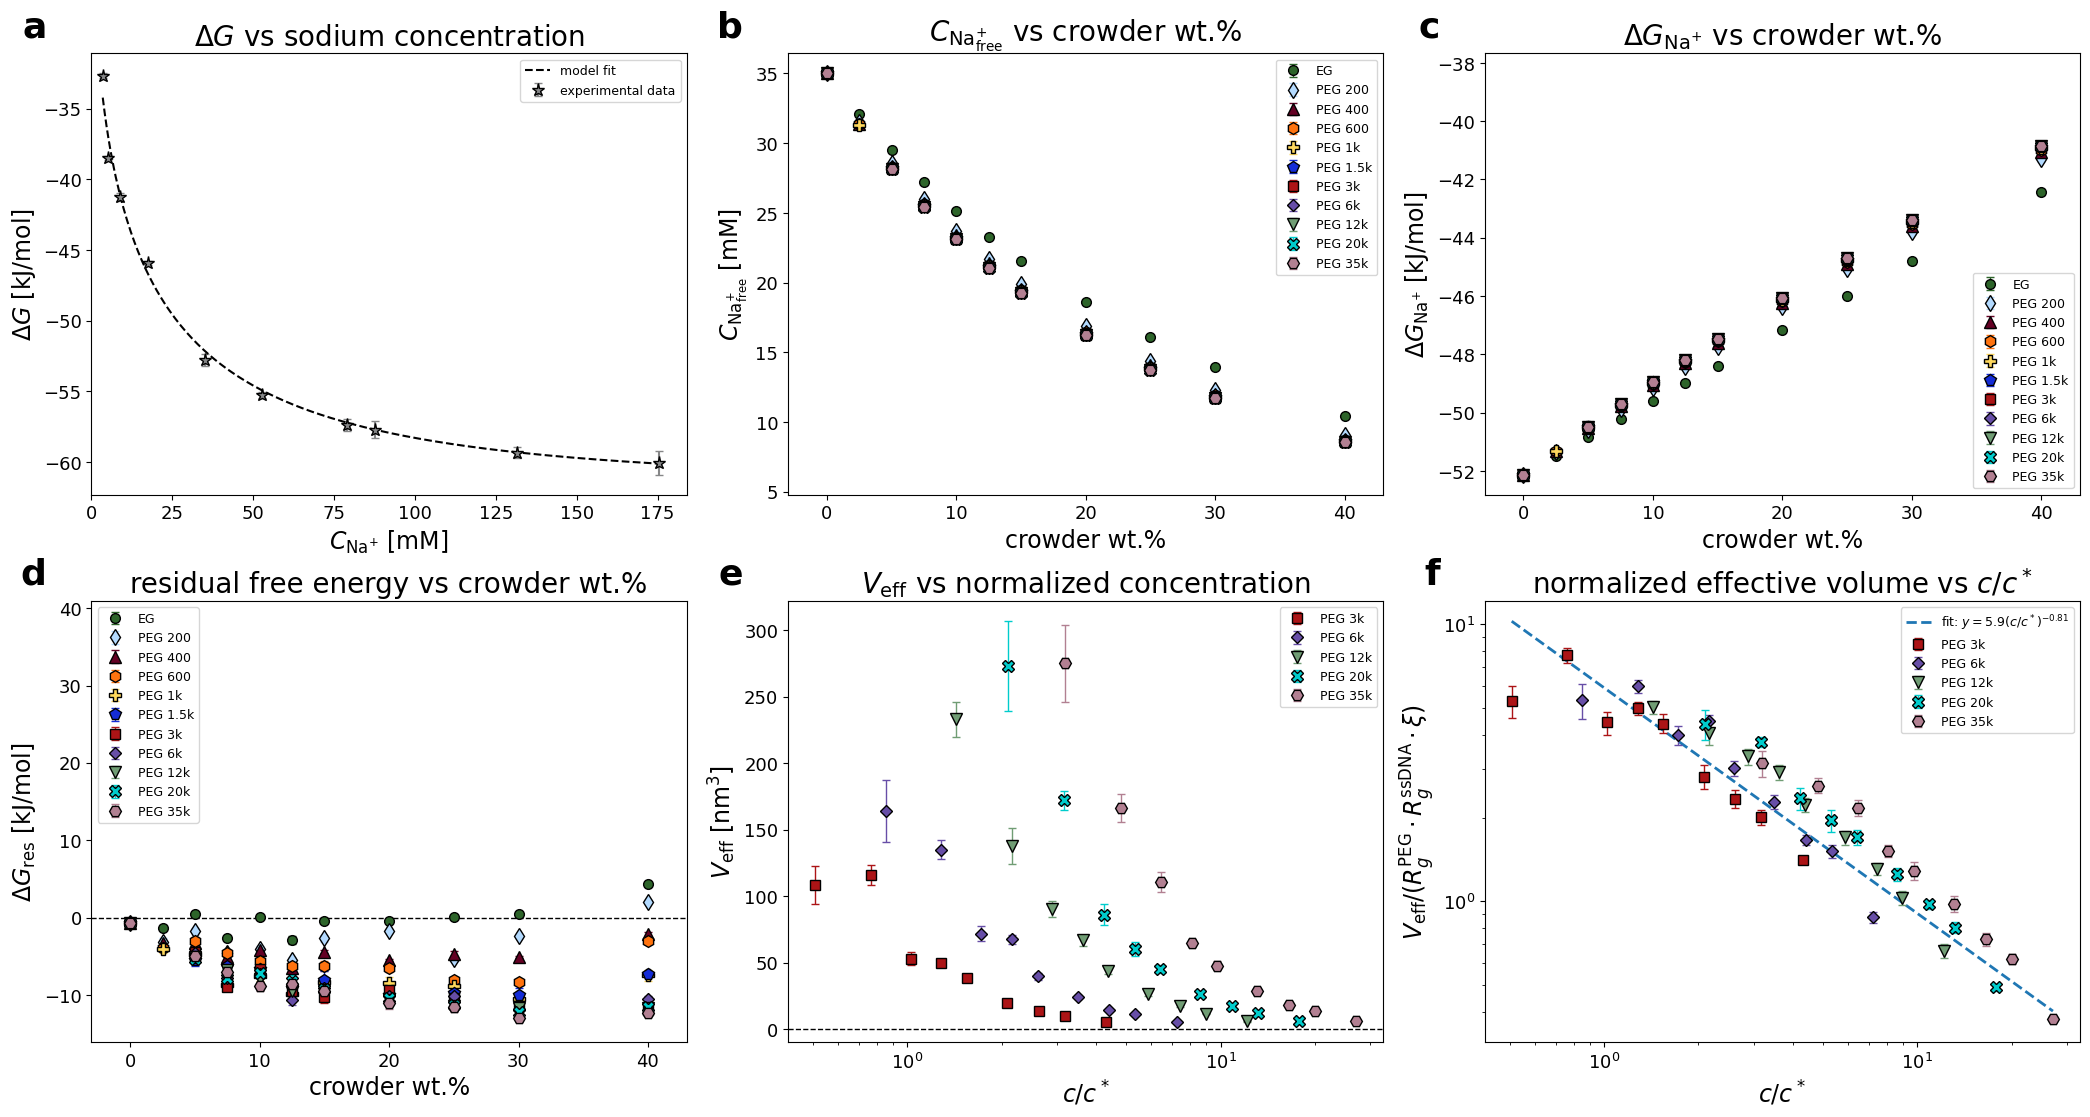

In [29]:
# Figure 4: panels a-f on a 2 x 3 grid
fig, axes = plt.subplots(2, 3, figsize=(3 * PANEL_W, 2 * PANEL_H))

panels = [
    ('a', panel_4a), ('b', panel_4b), ('c', panel_4c),
    ('d', panel_4d), ('e', panel_4e), ('f', panel_4f),
]

for ax, (letter, draw_panel) in zip(axes.flat, panels):
    draw_panel(ax)

fig.tight_layout()

for ax, (letter, _) in zip(axes.flat, panels):
    label_panel(ax, letter)
save_figure(fig, 'figure4')
plt.show()